# Sentiment Analysis Detection

This notebook follows the TweetEval text-classification workflow to classify tweets as **negative**, **neutral**, or **positive**. It explores the official train, validation, and test splits; cleans and normalizes tweet text; compares BoW, TF-IDF, and Word2Vec baselines; tunes classical classifiers using stratified cross-validation; selects a model by validation macro F1; and evaluates it once on the test split.

**Environment:** Use the project `.venv313` Python 3.13 kernel. The workflow uses Hugging Face Datasets, scikit-learn, NLTK, Emoji, Gensim, pandas, seaborn, and Matplotlib. The NLTK setup cell downloads WordNet and the English POS tagger to NLTK's standard data location.

## 1. Load the dataset

In [1]:
from datasets import load_dataset
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import emoji

# Official TweetEval sentiment data with train, validation, and test splits.
dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")

d:\ML-Lab\.venv313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
print(dataset)
print(f"Train: {len(dataset['train']):,} | Validation: {len(dataset['validation']):,} | Test: {len(dataset['test']):,}")

train_df = dataset["train"].to_pandas()
val_df = dataset["validation"].to_pandas()
test_df = dataset["test"].to_pandas()

# TweetEval sentiment ids: 0 = negative, 1 = neutral, 2 = positive.
sentiment_labels = {0: "negative", 1: "neutral", 2: "positive"}
for frame in (train_df, val_df, test_df):
    frame["sentiment"] = frame["label"].map(sentiment_labels)

display(train_df.head())

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 45615
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 12284
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 2000
    })
})
Train: 45,615 | Validation: 2,000 | Test: 12,284


,text,label,sentiment
0,"""QT @user In the original draft of the 7th boo...",2,positive
1,"""Ben Smith / Smith (concussion) remains out of...",1,neutral
2,Sorry bout the stream last night I crashed out...,1,neutral
3,Chase Headley's RBI double in the 8th inning o...,1,neutral
4,@user Alciato: Bee will invest 150 million in ...,2,positive


## 2. Exploratory Data Analysis

In [3]:
sns.set_theme(style="whitegrid")
# Dataset overview and data quality by split.
dataset_splits = {"train": train_df, "validation": val_df, "test": test_df}
overview = pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "missing_cells": int(frame.isna().sum().sum()),
        "duplicate_rows": int(frame.duplicated().sum()),
        "duplicate_tweets": int(frame["text"].duplicated().sum()),
    }
    for name, frame in dataset_splits.items()
])
display(overview)
print("Training columns and types:")
display(train_df.dtypes.to_frame("dtype"))
print("Training examples:")
display(train_df[["text", "sentiment"]].sample(5))

,split,rows,missing_cells,duplicate_rows,duplicate_tweets
0,train,45615,0,26,29
1,validation,2000,0,0,0
2,test,12284,0,0,0


Training columns and types:


,dtype
text,str
label,int64
sentiment,str


Training examples:


,text,sentiment
40370,JR Smith wanna be a starter so damn bad lol\u0...,neutral
44162,The Americans may not have won the opening nig...,positive
4469,@user have you watched Four Lions? Saw it agai...,positive
43548,HALL OF FAMER Frank Gifford a NFL Legend on th...,positive
26098,Ortiz post team-record 9th 30-homer season wit...,positive


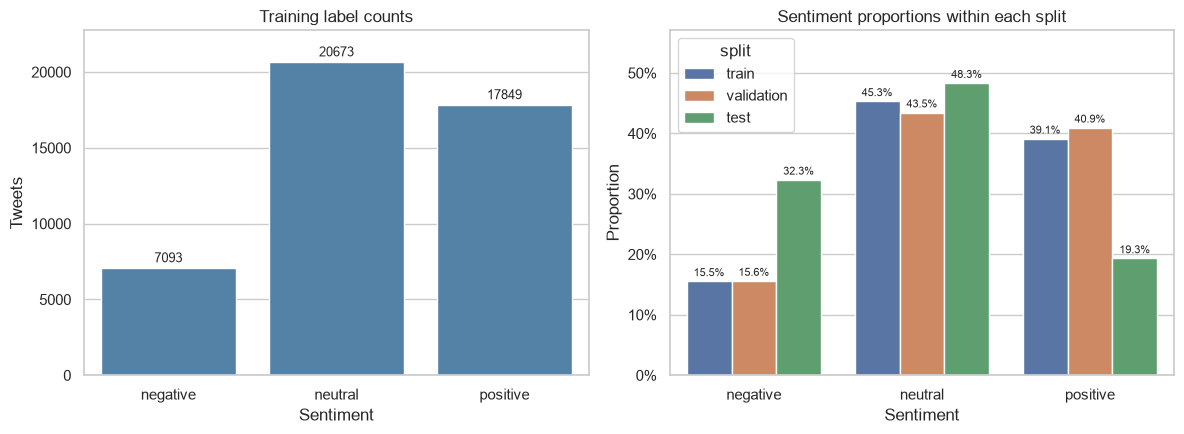

In [4]:
# Compare sentiment counts and within-split proportions across the official splits.
from matplotlib.ticker import PercentFormatter

label_names = list(sentiment_labels.values())
counts = pd.DataFrame({
    name: frame["sentiment"].value_counts().reindex(label_names, fill_value=0)
    for name, frame in dataset_splits.items()
})
proportions = counts.div(counts.sum(axis=0), axis=1).rename_axis("sentiment").reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.countplot(
    data=train_df, x="sentiment", order=label_names,
    ax=axes[0], color="steelblue",
)
axes[0].set(title="Training label counts", xlabel="Sentiment", ylabel="Tweets")
axes[0].margins(y=0.10)
for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f", padding=2, fontsize=9)

proportion_data = proportions.melt(
    id_vars="sentiment", var_name="split", value_name="proportion"
)
sns.barplot(
    data=proportion_data, x="sentiment", y="proportion", hue="split",
    order=label_names, ax=axes[1],
)
axes[1].set(
    title="Sentiment proportions within each split",
    xlabel="Sentiment",
    ylabel="Proportion",
)
axes[1].yaxis.set_major_formatter(PercentFormatter(xmax=1))
axes[1].margins(y=0.18)
for container in axes[1].containers:
    labels = [f"{bar.get_height():.1%}" for bar in container]
    axes[1].bar_label(container, labels=labels, padding=2, fontsize=8)

plt.tight_layout()
plt.show()


,count,mean,std,min,25%,50%,75%,max
sentiment,,,,,,,,
negative,7093.0,20.2,4.8,4.0,17.0,21.0,24.0,35.0
neutral,20673.0,19.0,4.9,1.0,16.0,19.0,23.0,33.0
positive,17849.0,19.1,5.0,4.0,16.0,19.0,23.0,34.0


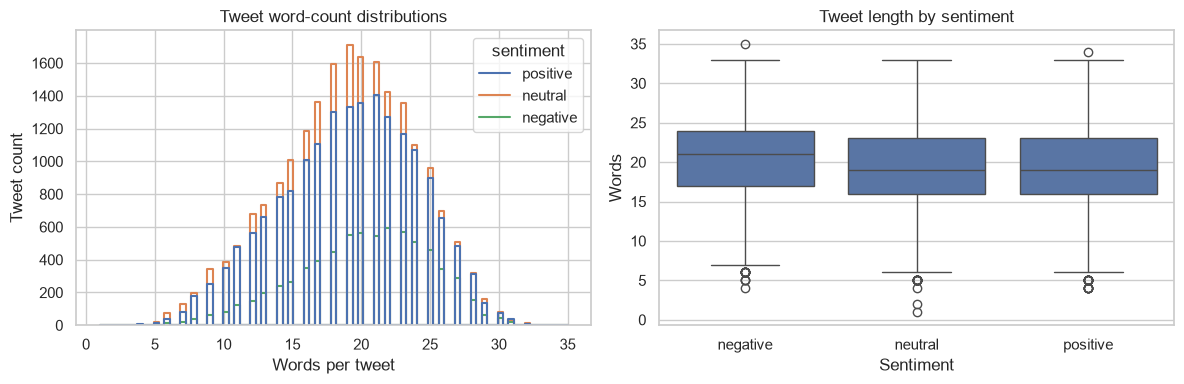

In [5]:
# Tweet length by words and characters.
train_df["word_count"] = train_df["text"].astype(str).str.split().str.len()
# train_df["char_count"] = train_df["text"].astype(str).str.len()
display(train_df.groupby("sentiment")["word_count"].describe().round(1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=train_df, x="word_count", hue="sentiment", stat="count",
             element="step", fill=False, ax=axes[0])
sns.boxplot(data=train_df, x="sentiment", y="word_count", order=label_names, ax=axes[1])
axes[0].set(title="Tweet word-count distributions", xlabel="Words per tweet", ylabel="Tweet count")
axes[1].set(title="Tweet length by sentiment", xlabel="Sentiment", ylabel="Words")
plt.tight_layout()
plt.show()

### Word frequencies and word clouds

Frequencies below are calculated from training tweets only. The light cleanup removes links and usernames while retaining hashtag words.

Top 10 words overall (stopwords included):


,word,count
0,the,38017
1,to,20952
2,i,16900
3,in,13717
4,on,13121
5,a,13058
6,and,12701
7,of,10899
8,s,10725
9,u,10136


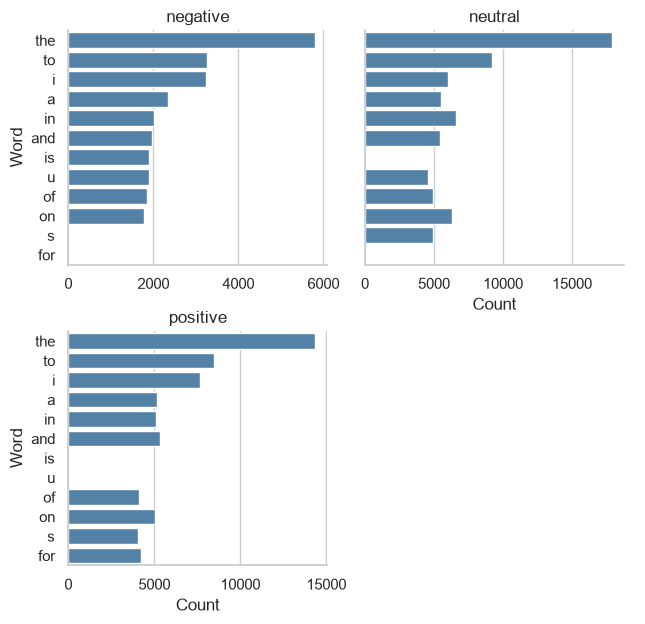

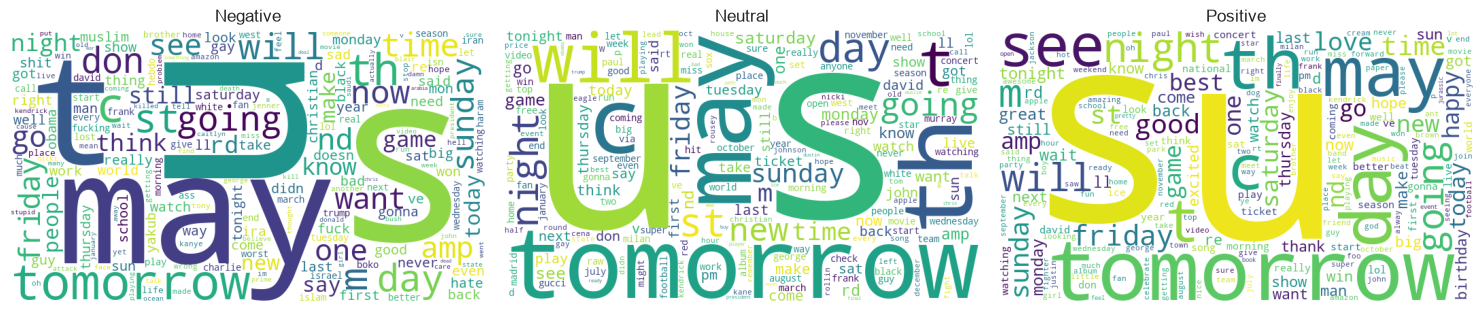

In [6]:
import re
from collections import Counter
from wordcloud import WordCloud

def words_for_eda(text):
    text = emoji.demojize(str(text).lower())
    text = re.sub(r"https?://\S+|www\.\S+|(?<!\w)@\w+", " ", text)
    text = re.sub(r"#(\w+)", r"\1", text)
    return re.findall(r"[a-z]+", text)

# The table and bars count all extracted words, including stopwords.
word_counts = Counter(
    word for tweet in train_df["text"] for word in words_for_eda(tweet)
)
print("Top 10 words overall (stopwords included):")
display(pd.DataFrame(word_counts.most_common(10), columns=["word", "count"]))

# Top words for each sentiment, also including stopwords.
top_words = []
for sentiment in label_names:
    sentiment_counts = Counter(
        word
        for tweet in train_df.loc[train_df["sentiment"].eq(sentiment), "text"]
        for word in words_for_eda(tweet)
    )
    top_words.extend(
        {"sentiment": sentiment, "word": word, "count": count}
        for word, count in sentiment_counts.most_common(10)
    )
top_words = pd.DataFrame(top_words)
grid = sns.catplot(
    data=top_words, x="count", y="word", col="sentiment",
    col_order=label_names, col_wrap=2, kind="bar", sharex=False,
    height=3.2, color="steelblue",
)
grid.set_titles("{col_name}")
grid.set_axis_labels("Count", "Word")
plt.show()

# WordCloud filters its default stopword list.
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, sentiment in zip(axes.flat, label_names):
    text = " ".join(
        word
        for tweet in train_df.loc[train_df["sentiment"].eq(sentiment), "text"]
        for word in words_for_eda(tweet)
    )
    ax.imshow(WordCloud(
        width=700, height=400, background_color="white",
        collocations=False,
    ).generate(text))
    ax.set_title(sentiment.title())
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3. Clean, normalize, tokenize, and lemmatize

NLTK's WordNet lemmatizer uses POS tags to choose the correct base form. The setup cell downloads WordNet, OMW, and the English POS tagger to NLTK.

The cleaner retains hashtag words, emoji and emoticons, negations, intensity and contrast words. It converts emphasis punctuation to text cues, normalizes repeated characters, removes URLs, HTML tags and mentions, tokenizes, optionally removes stopwords, and lemmatizes.

### Handle duplicate training tweets

Remove repeated training text before tokenization so identical examples do not receive extra weight. Report and exclude training text groups with conflicting labels instead of choosing an arbitrary label. The next step also removes validation text shared with test; test rows remain unchanged.

In [7]:
# Exact duplicate tweet text with different labels cannot be separated by a text model.
duplicate_label_counts = train_df.groupby("text")["label"].nunique()
conflicting_texts = duplicate_label_counts[duplicate_label_counts.gt(1)].index
conflicting_rows = train_df["text"].isin(conflicting_texts)

conflicting_group_count = len(conflicting_texts)
conflicting_row_count = int(conflicting_rows.sum())
print(
    f"Conflicting training texts: {conflicting_group_count:,} groups "
    f"({conflicting_row_count:,} rows)."
)
if conflicting_group_count:
    print("Examples of conflicting text and labels:")
    display(
        train_df.loc[conflicting_rows, ["text", "label"]]
        .sort_values(["text", "label"])
        .head(20)
    )

train_rows_before = len(train_df)
train_df = (
    train_df.loc[~conflicting_rows]
    .drop_duplicates(subset="text", keep="first")
    .reset_index(drop=True)
)
dataset_splits["train"] = train_df
removed_training_rows = train_rows_before - len(train_df)
print(
    f"Removed {removed_training_rows:,} training rows from conflicting or "
    f"repeated text groups; train rows now: {len(train_df):,}."
)

Conflicting training texts: 3 groups (6 rows).
Examples of conflicting text and labels:


,text,label
16929,An emotionally intelligent organisation throug...,1
18334,An emotionally intelligent organisation throug...,2
43865,Buses to replace train services on Sunday as f...,1
16293,Buses to replace train services on Sunday as f...,2
45079,Not making it to the main debate stage may not...,0
28331,Not making it to the main debate stage may not...,1


Removed 32 training rows from conflicting or repeated text groups; train rows now: 45,583.


### Check and prevent exact text overlap across splits

Keep the test split unchanged. Remove any training text also found in validation or test, and remove validation text also found in test, so the final evaluation split stays separate from model fitting and selection.

In [8]:
# Report raw overlap, then remove overlapping rows from training and validation.
raw_split_pairs = (("train", train_df), ("validation", val_df), ("test", test_df))
raw_overlap_rows = []
for left_index in range(len(raw_split_pairs)):
    left_name, left_frame = raw_split_pairs[left_index]
    for right_name, right_frame in raw_split_pairs[left_index + 1:]:
        shared_texts = set(left_frame["text"]) & set(right_frame["text"])
        raw_overlap_rows.append({
            "Split pair": f"{left_name} / {right_name}",
            "Shared exact tweets before cleanup": len(shared_texts),
        })
display(pd.DataFrame(raw_overlap_rows))

validation_texts = set(val_df["text"])
test_texts = set(test_df["text"])
training_texts_to_exclude = set(train_df["text"]) & (validation_texts | test_texts)
if training_texts_to_exclude:
    rows_before = len(train_df)
    train_df = train_df.loc[
        ~train_df["text"].isin(training_texts_to_exclude)
    ].reset_index(drop=True)
    print(
        f"Removed {rows_before - len(train_df):,} training rows whose text "
        "also appears in validation or test."
    )

validation_texts_in_test = set(val_df["text"]) & test_texts
if validation_texts_in_test:
    rows_before = len(val_df)
    val_df = val_df.loc[
        ~val_df["text"].isin(validation_texts_in_test)
    ].reset_index(drop=True)
    print(
        f"Removed {rows_before - len(val_df):,} validation rows whose text "
        "also appears in test; test rows are unchanged."
    )

dataset_splits["train"] = train_df
dataset_splits["validation"] = val_df
final_split_pairs = (("train", train_df), ("validation", val_df), ("test", test_df))
final_overlap_rows = []
for left_index in range(len(final_split_pairs)):
    left_name, left_frame = final_split_pairs[left_index]
    for right_name, right_frame in final_split_pairs[left_index + 1:]:
        shared_texts = set(left_frame["text"]) & set(right_frame["text"])
        final_overlap_rows.append({
            "Split pair": f"{left_name} / {right_name}",
            "Shared exact tweets after cleanup": len(shared_texts),
        })
final_split_overlap = pd.DataFrame(final_overlap_rows)
display(final_split_overlap)
if final_split_overlap["Shared exact tweets after cleanup"].gt(0).any():
    raise ValueError("Exact text overlap remains after split cleanup; inspect the affected rows.")

,Split pair,Shared exact tweets before cleanup
0,train / validation,0
1,train / test,0
2,validation / test,0


,Split pair,Shared exact tweets after cleanup
0,train / validation,0
1,train / test,0
2,validation / test,0


In [9]:
import nltk
from nltk.stem import WordNetLemmatizer

required_nltk_resources = (
    "wordnet",
    "omw-1.4",
    "averaged_perceptron_tagger_eng",
)
for resource in required_nltk_resources:
    nltk.download(resource, quiet=False)

lemmatizer = WordNetLemmatizer()
print("NLTK data search locations:")
for location in nltk.data.path:
    print(" -", location)
print("WordNet check:", lemmatizer.lemmatize("cars"))
print("POS tagger check:", nltk.pos_tag(["running"]))


[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\panha\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\panha\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\panha\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


NLTK data search locations:
 - C:\Users\panha/nltk_data
 - d:\ML-Lab\.venv313\nltk_data
 - d:\ML-Lab\.venv313\share\nltk_data
 - d:\ML-Lab\.venv313\lib\nltk_data
 - C:\Users\panha\AppData\Roaming\nltk_data
 - C:\nltk_data
 - D:\nltk_data
 - E:\nltk_data
WordNet check: car
POS tagger check: [('running', 'VBG')]


In [10]:
import html
import re
import unicodedata
import nltk
from nltk.tokenize import TweetTokenizer
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

lemmatizer = WordNetLemmatizer()
tweet_tokenizer = TweetTokenizer(preserve_case=False)
keep_words = {
    "no",
    "nor",
    "not",
    "never",
    "very",
    "too",
    "so",
    "more",
    "most",
    "less",
    "but",
    "however",
    "yet",
    "up",
    "down",
}
stop_words = set(ENGLISH_STOP_WORDS) - keep_words

contractions = {
    "can't": "can not",
    "won't": "will not",
    "shan't": "shall not",
    "ain't": "not",
    "don't": "do not",
    "doesn't": "does not",
    "didn't": "did not",
    "isn't": "is not",
    "aren't": "are not",
    "wasn't": "was not",
    "weren't": "were not",
    "hasn't": "has not",
    "haven't": "have not",
    "hadn't": "had not",
    "couldn't": "could not",
    "wouldn't": "would not",
    "shouldn't": "should not",
    "mustn't": "must not",
    "needn't": "need not",
    "mightn't": "might not",
    "i'm": "i am",
    "you're": "you are",
    "we're": "we are",
    "they're": "they are",
    "i've": "i have",
    "you've": "you have",
    "we've": "we have",
    "they've": "they have",
    "i'll": "i will",
    "you'll": "you will",
    "he'll": "he will",
    "she'll": "she will",
    "it'll": "it will",
    "we'll": "we will",
    "they'll": "they will",
    "let's": "let us",
}
contraction_pattern = re.compile(
    r"\b(?:"
    + "|".join(re.escape(item) for item in sorted(contractions, key=len, reverse=True))
    + r")\b",
    flags=re.IGNORECASE,
)

# Convert common ASCII emoticons before removing punctuation.
emoticon_variants = {
    "emoticon_broken_heart": ["</3"],
    "emoticon_heart": ["<3"],
    "emoticon_wink": [";)", ";-)", ";]", ";-]"],
    "emoticon_playful": [":p", ":-p", ";p", ";-p"],
    "emoticon_positive": [
        ":)",
        ":-)",
        ":]",
        ":-]",
        ":d",
        ":-d",
        "=)",
        "=-)",
        "(:",
        "(-:",
    ],
    "emoticon_negative": [
        ":(",
        ":-(",
        ":[",
        ":-[",
        "=(",
        "=-(",
        ":'(",
        ":'-(",
        "):",
        ")-:",
    ],
    "emoticon_neutral": [":|", ":-|", ":/", ":-/", ":\\", ":-\\", ":o", ":-o"],
}
emoticon_map = {
    variant.lower(): label
    for label, variants in emoticon_variants.items()
    for variant in variants
}
emoticon_pattern = re.compile(
    r"(?<![A-Za-z0-9])(?:"
    + "|".join(re.escape(item) for item in sorted(emoticon_map, key=len, reverse=True))
    + r")(?![A-Za-z0-9])",
    flags=re.IGNORECASE,
)


def clean_tweet(text):
    text = html.unescape(str(text))
    text = text.replace("\u2019", "'").replace("\u2018", "'")
    text = contraction_pattern.sub(
        lambda match: contractions[match.group(0).lower()], text
    )
    text = emoticon_pattern.sub(
        lambda match: f" {emoticon_map[match.group(0).lower()]} ", text
    )
    text = emoji.demojize(text)
    # Remove HTML tags such as <br> and <b>.
    text = re.sub(r"<[^>]+>", " ", text)

    # Remove links that start with http://, https://, or www.
    # The URL match continues until whitespace.
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)

    # Remove @mentions made of letters, digits, or underscores.
    # (?<!\w) prevents matching an @ that appears inside another word.
    text = re.sub(r"(?<!\w)@\w+", " ", text)

    # Remove the # symbol but keep the hashtag words for classification.
    # Split hashtags at lowercase-to-uppercase boundaries,
    # so #SoHappy becomes "So Happy".
    text = re.sub(
        r"#(\w+)",
        lambda match: re.sub(r"([a-z])([A-Z])", r"\1 \2", match.group(1)),
        text,
    )

    # Preserve expressive punctuation as words before removing punctuation.
    text = re.sub(r"!+", " exclamation_mark ", text)
    text = re.sub(r"\?+", " question_mark ", text)
    text = re.sub(r"\.{2,}", " ellipsis ", text)

    # Limit any run of 3+ identical characters to two,
    # reducing stretched spellings while retaining emphasis (soooo -> soo).
    text = re.sub(r"(.)\1{2,}", r"\1\1", text)

    text = text.lower()
    return "".join(
        " " if unicodedata.category(char).startswith("P") and char != "_" else char
        for char in text
    ).strip()


def wordnet_pos(penn_tag):
    """Map a Penn Treebank tag to the WordNet POS labels."""
    if penn_tag.startswith("J"):
        return "a"
    if penn_tag.startswith("V"):
        return "v"
    if penn_tag.startswith("R"):
        return "r"
    return "n"


def tokenize_normalize(text, remove_stopwords=False, lemmatize=True):
    tokens = tweet_tokenizer.tokenize(clean_tweet(text))

    if remove_stopwords:
        tokens = [
            token for token in tokens if not (token.isalpha() and token in stop_words)
        ]

    # POS-tag regular words and preserve emoji/emoticon placeholders.
    word_positions = [i for i, token in enumerate(tokens) if token.isalpha()]
    if lemmatize and word_positions:
        tagged_words = nltk.pos_tag([tokens[i] for i in word_positions])
        for index, (word, tag) in zip(word_positions, tagged_words):
            tokens[index] = lemmatizer.lemmatize(word, wordnet_pos(tag))

    return tokens


example = "@user I am sooo happy!!! #GreatDay https://example.com Ã°Å¸Ëœâ€ž :) :( :D <3 </3"
print("Cleaned:", clean_tweet(example))
print("Lemmatized tokens:", tokenize_normalize(example))

Cleaned: i am soo happy exclamation_mark  great day  ã°å¸ëœâ€ž  emoticon_positive  emoticon_negative  emoticon_positive  emoticon_heart  emoticon_broken_heart
Lemmatized tokens: ['i', 'be', 'soo', 'happy', 'exclamation_mark', 'great', 'day', 'ã', '°', 'å', '¸', 'ëœâ', '€', 'ž', 'emoticon_positive', 'emoticon_negative', 'emoticon_positive', 'emoticon_heart', 'emoticon_broken_heart']


In [11]:
# Use WordNet-lemmatized tokens for the main models and retain variants for comparison.
for frame in dataset_splits.values():
    frame["tokens"] = frame["text"].map(tokenize_normalize)
    frame["tokens_no_stopwords"] = frame["text"].map(
        lambda text: tokenize_normalize(text, remove_stopwords=True)
    )
    frame["tokens_unlemmatized"] = frame["text"].map(
        lambda text: tokenize_normalize(text, lemmatize=False)
    )

display(train_df[
    ["text", "tokens", "tokens_no_stopwords", "tokens_unlemmatized", "sentiment"]
].head())


,text,tokens,tokens_no_stopwords,tokens_unlemmatized,sentiment
0,"""QT @user In the original draft of the 7th boo...","[qt, in, the, original, draft, of, the, 7th, b...","[qt, original, draft, 7th, book, remus, lupin,...","[qt, in, the, original, draft, of, the, 7th, b...",positive
1,"""Ben Smith / Smith (concussion) remains out of...","[ben, smith, smith, concussion, remain, out, o...","[ben, smith, smith, concussion, remain, lineup...","[ben, smith, smith, concussion, remains, out, ...",neutral
2,Sorry bout the stream last night I crashed out...,"[sorry, bout, the, stream, last, night, i, cra...","[sorry, bout, stream, night, crash, but, tonig...","[sorry, bout, the, stream, last, night, i, cra...",neutral
3,Chase Headley's RBI double in the 8th inning o...,"[chase, headley, s, rbi, double, in, the, 8th,...","[chase, headley, s, rbi, double, 8th, inning, ...","[chase, headley, s, rbi, double, in, the, 8th,...",neutral
4,@user Alciato: Bee will invest 150 million in ...,"[alciato, bee, will, invest, 150, million, in,...","[alciato, bee, invest, 150, million, january, ...","[alciato, bee, will, invest, 150, million, in,...",positive


## 4. Compare preprocessing options

Use the validation split to compare lemmatization and stopword removal with the same TF-IDF and Logistic Regression baseline. Select the token version by macro F1; keep the test split for final evaluation only.


In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def identity_tokenizer(tokens):
    return tokens

def metric_scores(y_true, y_pred):
    scores = {"Accuracy": accuracy_score(y_true, y_pred)}
    for average in ("macro", "weighted"):
        precision, recall, f1, _ = precision_recall_fscore_support(
            y_true, y_pred, average=average, zero_division=0
        )
        scores.update({
            f"Precision ({average})": precision,
            f"Recall ({average})": recall,
            f"F1-score ({average})": f1,
        })
    return scores


def fit_and_score(model, X_train, y_train, X_eval, y_eval):
    """Fit a classifier, predict the evaluation split, and return all metrics."""
    model.fit(X_train, y_train)
    predictions = model.predict(X_eval)
    return model, metric_scores(y_eval, predictions)


def make_tfidf():
    return TfidfVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False, ngram_range=(1, 2), min_df=2, sublinear_tf=True,
    )

preprocessing_options = [
    ("Lemmatization; stopwords kept", "tokens"),
    ("Lemmatization; stopwords removed", "tokens_no_stopwords"),
    ("No lemmatization; stopwords kept", "tokens_unlemmatized"),
]
preprocessing_results = []
for name, token_column in preprocessing_options:
    vectorizer = make_tfidf()
    X_train = vectorizer.fit_transform(train_df[token_column].tolist())
    X_val = vectorizer.transform(val_df[token_column].tolist())
    model, scores = fit_and_score(
        LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
        X_train, train_df["label"], X_val, val_df["label"],
    )
    preprocessing_results.append({
        "Preprocessing": name,
        "Accuracy": scores["Accuracy"],
        "Macro F1": scores["F1-score (macro)"],
        "token_column": token_column,
    })

preprocessing_results_df = pd.DataFrame(preprocessing_results).sort_values(
    "Macro F1", ascending=False
).reset_index(drop=True)
selected_token_column = preprocessing_results_df.loc[0, "token_column"]
display(preprocessing_results_df.drop(columns="token_column").round(3))
print("Selected preprocessing:", preprocessing_results_df.loc[0, "Preprocessing"])


,Preprocessing,Accuracy,Macro F1
0,Lemmatization; stopwords kept,0.679,0.659
1,No lemmatization; stopwords kept,0.679,0.658
2,Lemmatization; stopwords removed,0.676,0.656


Selected preprocessing: Lemmatization; stopwords kept


## 5. Train baseline models

Compare BoW and TF-IDF with Logistic Regression, Linear SVM, and Multinomial Naive Bayes. Compare mean-pooled Word2Vec embeddings with Logistic Regression, Linear SVM, and Gaussian Naive Bayes, which supports signed continuous vectors. Evaluate every baseline on the validation split.

In [13]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

def make_vectorizer(feature_type):
    options = dict(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False, min_df=2,
    )
    if feature_type == "bow":
        return CountVectorizer(**options)
    return TfidfVectorizer(
        **options, ngram_range=(1, 2), sublinear_tf=True
    )

train_tokens = train_df[selected_token_column].tolist()
val_tokens = val_df[selected_token_column].tolist()
y_train = train_df["label"].to_numpy()
y_val = val_df["label"].to_numpy()
y_test = test_df["label"].to_numpy()

sparse_model_factories = {
    "Logistic Regression": lambda: LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Linear SVM": lambda: LinearSVC(class_weight="balanced", random_state=42),
    "Multinomial Naive Bayes": lambda: MultinomialNB(alpha=1.0),
}
results, fitted_models = [], {}

for feature_name, feature_type in (
    ("BoW unigrams", "bow"),
    ("TF-IDF unigrams + bigrams", "tfidf"),
):
    transformer = make_vectorizer(feature_type)
    X_train_features = transformer.fit_transform(train_tokens)
    X_val_features = transformer.transform(val_tokens)
    for model_name, make_model in sparse_model_factories.items():
        model, scores = fit_and_score(
            make_model(), X_train_features, y_train, X_val_features, y_val
        )
        run_id = f"{feature_name} | {model_name}"
        results.append({
            "run_id": run_id, "Features": feature_name, "Model": model_name,
            **scores,
        })
        fitted_models[run_id] = {
            "kind": "sparse", "transformer": transformer, "model": model,
        }

### Word2Vec features

Train a CBOW Word2Vec model using training tweets only. Average known word vectors to create one feature vector per tweet, then compare Logistic Regression, Linear SVM, and Gaussian Naive Bayes. Gaussian Naive Bayes handles the signed, continuous embedding values.

In [14]:
from gensim.models import Word2Vec
from sklearn.naive_bayes import GaussianNB
import numpy as np

def average_word2vec(token_lists, embedding):
    tweet_vectors = []
    for tokens in token_lists:
        word_vectors = [embedding.wv[token] for token in tokens if token in embedding.wv]
        tweet_vectors.append(
            np.mean(word_vectors, axis=0) if word_vectors
            else np.zeros(embedding.vector_size)
        )
    return np.asarray(tweet_vectors, dtype=np.float32)

embedding = Word2Vec(
    sentences=train_tokens, vector_size=100, window=5, min_count=2,
    workers=1, sg=0, epochs=15, seed=42,
)
X_train_w2v = average_word2vec(train_tokens, embedding)
X_val_w2v = average_word2vec(val_tokens, embedding)

word2vec_model_factories = {
    "Logistic Regression": lambda: LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=42
    ),
    "Linear SVM": lambda: LinearSVC(class_weight="balanced", random_state=42),
    "Gaussian Naive Bayes": lambda: GaussianNB(),
}
for model_name, make_model in word2vec_model_factories.items():
    model = make_model().fit(X_train_w2v, y_train)
    predictions = model.predict(X_val_w2v)
    run_id = f"Word2Vec CBOW (100d mean) | {model_name}"
    results.append({
        "run_id": run_id, "Features": "Word2Vec CBOW (100d mean)",
        "Model": model_name, **metric_scores(y_val, predictions),
    })
    fitted_models[run_id] = {
        "kind": "word2vec", "transformer": embedding, "model": model,
    }

print(f"Compared {len(results)} representation and model combinations.")

Compared 9 representation and model combinations.


## 6. Compare validation results

The table reports accuracy, macro precision, macro recall, macro F1, and weighted metrics for every representation and model. Macro F1 gives each of the three sentiment classes equal weight and is the main selection measure.

,Features,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Precision (weighted),Recall (weighted),F1-score (weighted)
0,TF-IDF unigrams + bigrams,Logistic Regression,0.679,0.651,0.681,0.659,0.695,0.679,0.683
1,TF-IDF unigrams + bigrams,Linear SVM,0.688,0.658,0.660,0.659,0.688,0.688,0.688
2,BoW unigrams,Logistic Regression,0.660,0.632,0.658,0.640,0.673,0.660,0.664
3,BoW unigrams,Linear SVM,0.640,0.616,0.628,0.621,0.644,0.640,0.642
4,BoW unigrams,Multinomial Naive Bayes,0.628,0.601,0.616,0.606,0.632,0.628,0.627
5,Word2Vec CBOW (100d mean),Linear SVM,0.576,0.540,0.550,0.544,0.582,0.576,0.579
6,Word2Vec CBOW (100d mean),Logistic Regression,0.541,0.528,0.556,0.523,0.584,0.541,0.550
7,Word2Vec CBOW (100d mean),Gaussian Naive Bayes,0.472,0.474,0.501,0.462,0.526,0.472,0.482
8,TF-IDF unigrams + bigrams,Multinomial Naive Bayes,0.618,0.753,0.490,0.456,0.686,0.618,0.570


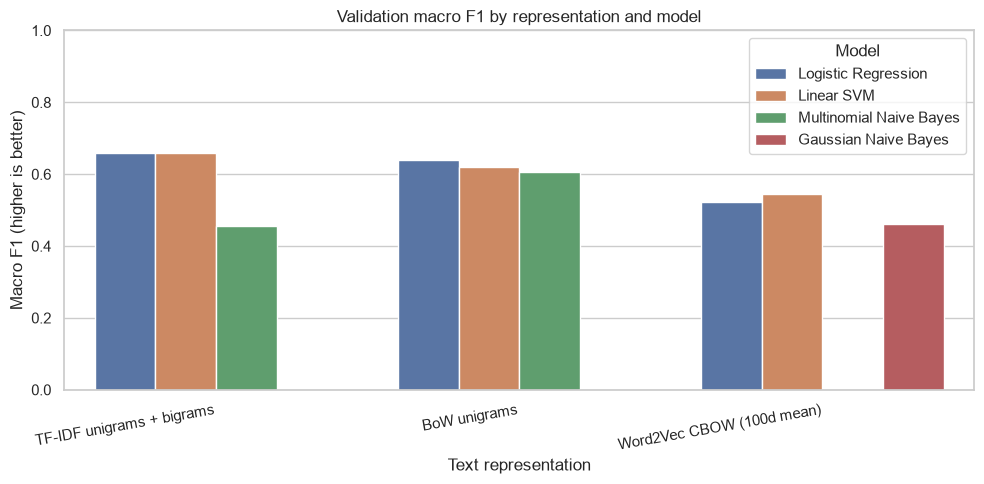

In [15]:
comparison_columns = [
    "Features", "Model", "Accuracy", "Precision (macro)", "Recall (macro)",
    "F1-score (macro)", "Precision (weighted)", "Recall (weighted)",
    "F1-score (weighted)",
]
results_df = pd.DataFrame(results).sort_values(
    "F1-score (macro)", ascending=False
).reset_index(drop=True)
display(results_df[comparison_columns].round(3))

fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(
    data=results_df, x="Features", y="F1-score (macro)", hue="Model", ax=ax
)
ax.set(title="Validation macro F1 by representation and model",
       xlabel="Text representation", ylabel="Macro F1 (higher is better)", ylim=(0, 1))
plt.xticks(rotation=10, ha="right")
plt.tight_layout()
plt.show()


## 7. Baseline comparison

Compare BoW, TF-IDF, and Word2Vec baselines on validation macro F1. Section 8 tunes the BoW and TF-IDF Logistic Regression, Linear SVM, and Multinomial Naive Bayes pipelines, then compares all candidates on the same validation split.

In [16]:
best_result = results_df.iloc[0]
best_model_info = fitted_models[best_result["run_id"]]
print("Initial baseline model:", best_result["Features"], "+", best_result["Model"])
display(best_result[comparison_columns].to_frame("Validation score").round(3))


Initial baseline model: TF-IDF unigrams + bigrams + Logistic Regression


,Validation score
Features,TF-IDF unigrams + bigrams
Model,Logistic Regression
Accuracy,0.679
Precision (macro),0.650608
Recall (macro),0.681455
F1-score (macro),0.659115
Precision (weighted),0.695069
Recall (weighted),0.679
F1-score (weighted),0.683043


## 8. Hyperparameter tuning and model selection

Tune BoW and word-level TF-IDF with Logistic Regression, Linear SVM, and Multinomial Naive Bayes, plus a combined word-and-character TF-IDF Linear SVM. Use stratified three-fold cross-validation on the training split, then compare each search's top 20 candidates on validation macro F1. The test split remains held out until final evaluation.

Each of the seven classifier pipelines samples 60 configurations, matching the reference search depth. Cross-validation ranks configurations by macro F1, which gives negative, neutral, and positive tweets equal weight even when their class counts differ.

### 8.1 Set up baselines and tuning settings

In [17]:
from sklearn.base import clone
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import FeatureUnion, Pipeline
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB

# The word branch accepts the existing token lists. The character branch joins
# each token list back into text before extracting character n-grams.
def join_token_lists(token_lists):
    return [" ".join(tokens) for tokens in token_lists]

scoring = {
    "accuracy": "accuracy",
    "macro_precision": make_scorer(precision_score, average="macro", zero_division=0),
    "macro_recall": make_scorer(recall_score, average="macro", zero_division=0),
    "macro_f1": make_scorer(f1_score, average="macro", zero_division=0),
}
cross_validation = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

word_level_params = {
    "ngram_range": [(1, 1), (1, 2), (1, 3)],
    "max_features": [None, 10000, 20000, 30000],
    "min_df": [1, 2, 3],
    "max_df": [0.90, 0.95, 1.0],
}

candidate_specs = {}
for representation, vectorizer in (
    ("TF-IDF", TfidfVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False,
    )),
    ("BoW", CountVectorizer(
        tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
        lowercase=False,
    )),
):
    for classifier_name, classifier in (
        ("Logistic Regression", LogisticRegression(random_state=42)),
        ("Linear SVM", LinearSVC(max_iter=5000, random_state=42)),
        ("Multinomial Naive Bayes", MultinomialNB()),
    ):
        vectorizer_step = "tfidf" if representation == "TF-IDF" else "bow"
        feature_params = {
            f"{vectorizer_step}__{key}": value
            for key, value in word_level_params.items()
        }
        if representation == "TF-IDF":
            feature_params[f"{vectorizer_step}__sublinear_tf"] = [False, True]
        else:
            feature_params[f"{vectorizer_step}__binary"] = [False, True]

        pipeline = Pipeline([
            (vectorizer_step, clone(vectorizer)),
            ("classifier", clone(classifier)),
        ])
        if classifier_name == "Logistic Regression":
            classifier_params = {
                "classifier__C": [0.01, 0.1, 1, 10, 100],
                "classifier__solver": ["lbfgs"],
                "classifier__class_weight": [None, "balanced"],
                "classifier__max_iter": [1000, 2000],
            }
        elif classifier_name == "Linear SVM":
            classifier_params = {
                "classifier__C": [0.01, 0.1, 1, 10, 100],
                "classifier__class_weight": [None, "balanced"],
            }
        else:
            classifier_params = {
                "classifier__alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0],
                "classifier__fit_prior": [True, False],
            }
        candidate_specs[f"Tuned {representation} + {classifier_name}"] = {
            "pipeline": pipeline,
            "parameters": {**feature_params, **classifier_params},
        }

word_char_pipeline = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            tokenizer=identity_tokenizer, preprocessor=None, token_pattern=None,
            lowercase=False,
        )),
        ("char", Pipeline([
            ("join_tokens", FunctionTransformer(join_token_lists, validate=False)),
            ("tfidf", TfidfVectorizer(
                analyzer="char_wb", lowercase=False, sublinear_tf=True,
            )),
        ])),
    ])),
    ("classifier", LinearSVC(max_iter=5000, random_state=42)),
])
word_char_parameters = {
    "features__word__ngram_range": [(1, 1), (1, 2)],
    "features__word__max_features": [None, 20000],
    "features__char__tfidf__ngram_range": [(2, 4), (2, 5), (3, 5)],
    "features__char__tfidf__min_df": [2, 4],
    "features__transformer_weights": [
        {"word": 1.0, "char": 1.0},
        {"word": 1.5, "char": 1.0},
    ],
    "classifier__C": [0.1, 1, 10],
    "classifier__class_weight": [None, "balanced"],
}
candidate_specs["Tuned word + character TF-IDF + Linear SVM"] = {
    "pipeline": word_char_pipeline,
    "parameters": word_char_parameters,
}

candidate_searches = {
    name: RandomizedSearchCV(
        estimator=spec["pipeline"],
        param_distributions=spec["parameters"],
        n_iter=60,
        scoring=scoring,
        refit="macro_f1",
        cv=cross_validation,
        random_state=42,
        n_jobs=2,
        return_train_score=False,
        verbose=1,
    )
    for name, spec in candidate_specs.items()
}
print(f"Configured {len(candidate_searches)} searches, sampling 60 settings per pipeline.")

Configured 7 searches, sampling 60 settings per pipeline.


### 8.2 Run the cross-validation searches


In [18]:
search_results = {}
for name, search in candidate_searches.items():
    print(f"Running {name}")
    search.fit(train_tokens, y_train)
    ranked = pd.DataFrame(search.cv_results_).sort_values("rank_test_macro_f1")
    search_results[name] = ranked
    display(ranked[[
        "rank_test_macro_f1", "mean_test_accuracy", "mean_test_macro_precision",
        "mean_test_macro_recall", "mean_test_macro_f1", "params",
    ]].head(10).rename(columns={
        "rank_test_macro_f1": "CV rank",
        "mean_test_accuracy": "CV accuracy",
        "mean_test_macro_precision": "CV macro precision",
        "mean_test_macro_recall": "CV macro recall",
        "mean_test_macro_f1": "CV macro F1",
    }).round(3))
    print("Best cross-validation macro F1:", round(search.best_score_, 3))

Running Tuned TF-IDF + Logistic Regression
Fitting 3 folds for each of 60 candidates, totalling 180 fits


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,params
3,1,0.663,0.636,0.662,0.644,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
2,2,0.663,0.635,0.662,0.644,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
13,3,0.661,0.634,0.660,0.642,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
12,4,0.660,0.633,0.660,0.641,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
50,5,0.660,0.632,0.659,0.641,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
48,6,0.663,0.638,0.642,0.640,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
30,7,0.657,0.631,0.660,0.639,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
9,8,0.657,0.631,0.659,0.639,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
35,9,0.656,0.629,0.658,0.637,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
8,10,0.669,0.649,0.625,0.634,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."


Best cross-validation macro F1: 0.644
Running Tuned TF-IDF + Linear SVM
Fitting 3 folds for each of 60 candidates, totalling 180 fits


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,params
4,1,0.670,0.643,0.646,0.644,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
10,2,0.668,0.640,0.646,0.643,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
1,3,0.667,0.640,0.646,0.642,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
46,4,0.656,0.630,0.632,0.631,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
30,5,0.653,0.625,0.632,0.628,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
3,6,0.652,0.623,0.632,0.627,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
13,7,0.651,0.623,0.632,0.627,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
21,8,0.652,0.624,0.629,0.626,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
25,9,0.655,0.635,0.619,0.625,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
8,10,0.657,0.640,0.611,0.622,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."


Best cross-validation macro F1: 0.644
Running Tuned TF-IDF + Multinomial Naive Bayes
Fitting 3 folds for each of 60 candidates, totalling 180 fits


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,params
2,1,0.634,0.604,0.614,0.608,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
29,2,0.613,0.593,0.630,0.597,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
55,3,0.612,0.589,0.624,0.596,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
47,4,0.612,0.591,0.627,0.596,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
3,5,0.620,0.594,0.601,0.595,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
31,6,0.611,0.589,0.625,0.595,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
17,7,0.611,0.587,0.616,0.594,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
41,8,0.611,0.589,0.624,0.594,"{'tfidf__sublinear_tf': False, 'tfidf__ngram_r..."
5,9,0.614,0.588,0.608,0.594,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."
21,9,0.614,0.588,0.608,0.594,"{'tfidf__sublinear_tf': True, 'tfidf__ngram_ra..."


... (5 outputs left out)

,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,params
36,1,0.637,0.609,0.615,0.611,"{'classifier__fit_prior': False, 'classifier__..."
26,2,0.633,0.604,0.622,0.610,"{'classifier__fit_prior': True, 'classifier__a..."
50,3,0.635,0.606,0.618,0.610,"{'classifier__fit_prior': True, 'classifier__a..."
48,4,0.631,0.602,0.625,0.609,"{'classifier__fit_prior': True, 'classifier__a..."
9,5,0.639,0.608,0.610,0.609,"{'classifier__fit_prior': True, 'classifier__a..."
24,6,0.627,0.599,0.624,0.607,"{'classifier__fit_prior': True, 'classifier__a..."
40,7,0.640,0.613,0.603,0.607,"{'classifier__fit_prior': True, 'classifier__a..."
45,8,0.626,0.598,0.622,0.606,"{'classifier__fit_prior': True, 'classifier__a..."
18,9,0.627,0.598,0.621,0.605,"{'classifier__fit_prior': True, 'classifier__a..."
51,10,0.628,0.600,0.614,0.605,"{'classifier__fit_prior': True, 'classifier__a..."


Best cross-validation macro F1: 0.611
Running Tuned word + character TF-IDF + Linear SVM
Fitting 3 folds for each of 60 candidates, totalling 180 fits


,CV rank,CV accuracy,CV macro precision,CV macro recall,CV macro F1,params
58,1,0.681,0.656,0.657,0.657,"{'features__word__ngram_range': (1, 2), 'featu..."
8,2,0.680,0.656,0.656,0.656,"{'features__word__ngram_range': (1, 2), 'featu..."
24,3,0.679,0.654,0.657,0.655,"{'features__word__ngram_range': (1, 2), 'featu..."
19,4,0.678,0.653,0.657,0.654,"{'features__word__ngram_range': (1, 2), 'featu..."
59,5,0.674,0.647,0.653,0.650,"{'features__word__ngram_range': (1, 1), 'featu..."
14,6,0.673,0.647,0.653,0.650,"{'features__word__ngram_range': (1, 1), 'featu..."
21,7,0.671,0.644,0.650,0.647,"{'features__word__ngram_range': (1, 1), 'featu..."
29,8,0.670,0.644,0.650,0.646,"{'features__word__ngram_range': (1, 1), 'featu..."
31,9,0.669,0.646,0.640,0.643,"{'features__word__ngram_range': (1, 2), 'featu..."
52,10,0.672,0.656,0.629,0.639,"{'features__word__ngram_range': (1, 2), 'featu..."


Best cross-validation macro F1: 0.657


In [19]:
word_char_search_name = "Tuned word + character TF-IDF + Linear SVM"
word_char_selected_parameters = candidate_searches[word_char_search_name].best_params_
print("Word-plus-character settings selected by cross-validation on sentiment training data:")
display(pd.DataFrame([
    {"Hyperparameter": name, "Selected value": str(value)}
    for name, value in word_char_selected_parameters.items()
]))

Word-plus-character settings selected by cross-validation on sentiment training data:


,Hyperparameter,Selected value
0,features__word__ngram_range,"(1, 2)"
1,features__word__max_features,None
2,features__transformer_weights,"{'word': 1.5, 'char': 1.0}"
3,features__char__tfidf__ngram_range,"(3, 5)"
4,features__char__tfidf__min_df,4
5,classifier__class_weight,balanced
6,classifier__C,0.1


### 8.3 Compare candidates on validation and select the model

For each search, fit the 20 highest-ranked cross-validation candidates on the training split and compare their macro F1 on validation. Include all baseline models in the same validation comparison. Select the model with the highest validation macro F1; do not use test results to choose it.

In [20]:
def evaluate_top_cv_candidates(search, ranked_results, top_n=20):
    """Fit top CV-ranked settings on train data and compare on validation."""
    shortlist = ranked_results.head(top_n)
    candidate_models = []
    candidate_scores = []
    candidate_parameters = []

    for parameters in shortlist["params"]:
        candidate = clone(search.estimator).set_params(**parameters)
        candidate.fit(train_tokens, y_train)
        predictions = candidate.predict(val_tokens)
        candidate_models.append(candidate)
        candidate_scores.append(metric_scores(y_val, predictions))
        candidate_parameters.append(parameters)

    best_index = max(
        range(len(candidate_scores)),
        key=lambda index: candidate_scores[index]["F1-score (macro)"],
    )
    table = pd.DataFrame([
        {
            "CV rank": int(shortlist.iloc[index]["rank_test_macro_f1"]),
            **scores,
            "Parameters": candidate_parameters[index],
        }
        for index, scores in enumerate(candidate_scores)
    ]).sort_values("F1-score (macro)", ascending=False).reset_index(drop=True)
    return {
        "scores": candidate_scores[best_index],
        "parameters": candidate_parameters[best_index],
        "pipeline": candidate_models[best_index],
        "table": table,
    }

tuned_validation = {}
for name, search in candidate_searches.items():
    candidate = evaluate_top_cv_candidates(search, search_results[name])
    tuned_validation[name] = candidate
    print(f"Top {name} settings on validation:")
    display(candidate["table"][[
        "CV rank", "Accuracy", "Precision (macro)",
        "Recall (macro)", "F1-score (macro)",
    ]].head(10).round(3))

# Make every baseline usable as a pipeline on raw token lists so any baseline
# can win validation selection and be refit on train plus validation.
def transform_word2vec(token_lists):
    return average_word2vec(token_lists, embedding)

model_options = {}
comparison_rows = []
for row in results_df.to_dict("records"):
    info = fitted_models[row["run_id"]]
    model_name = f"{row['Features']} + {row['Model']}"
    if info["kind"] == "sparse":
        pipeline = Pipeline([
            ("features", clone(info["transformer"])),
            ("classifier", clone(info["model"])),
        ])
    else:
        pipeline = Pipeline([
            ("word2vec", FunctionTransformer(transform_word2vec, validate=False)),
            ("classifier", clone(info["model"])),
        ])
    pipeline.fit(train_tokens, y_train)
    scores = metric_scores(y_val, pipeline.predict(val_tokens))
    model_options[model_name] = pipeline
    comparison_rows.append({"Model": model_name, **scores})

for model_name, candidate in tuned_validation.items():
    model_options[model_name] = candidate["pipeline"]
    comparison_rows.append({"Model": model_name, **candidate["scores"]})

metric_columns = [
    "Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"
]
validation_model_comparison = pd.DataFrame(comparison_rows).sort_values(
    "F1-score (macro)", ascending=False
).reset_index(drop=True)
display(validation_model_comparison[["Model", *metric_columns]].round(3))

selected_model_name = validation_model_comparison.iloc[0]["Model"]
best_model_info = {"pipeline": model_options[selected_model_name]}
selected_train_predictions = best_model_info["pipeline"].predict(train_tokens)
selected_val_predictions = best_model_info["pipeline"].predict(val_tokens)
training_accuracy = accuracy_score(y_train, selected_train_predictions)
validation_accuracy = accuracy_score(y_val, selected_val_predictions)
print("Final model selected using validation macro F1:", selected_model_name)
print(f"Training accuracy (in-sample): {training_accuracy:.3f}")
print(f"Validation accuracy: {validation_accuracy:.3f}")

Top Tuned TF-IDF + Logistic Regression settings on validation:


,CV rank,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,2,0.688,0.658,0.688,0.666
1,6,0.691,0.661,0.673,0.666
2,10,0.698,0.672,0.660,0.665
3,1,0.684,0.655,0.685,0.663
4,4,0.680,0.653,0.687,0.662
5,5,0.680,0.653,0.687,0.662
6,7,0.677,0.651,0.684,0.659
7,3,0.680,0.651,0.682,0.659
8,8,0.676,0.650,0.683,0.658
9,18,0.686,0.667,0.650,0.657


Top Tuned TF-IDF + Linear SVM settings on validation:


,CV rank,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,3,0.684,0.654,0.672,0.660
1,2,0.684,0.654,0.672,0.660
2,1,0.682,0.653,0.666,0.658
3,4,0.686,0.655,0.661,0.658
4,10,0.683,0.665,0.642,0.651
5,6,0.677,0.645,0.658,0.650
6,9,0.678,0.656,0.645,0.649
7,11,0.680,0.663,0.640,0.649
8,8,0.673,0.643,0.655,0.648
9,7,0.666,0.638,0.656,0.645


Top Tuned TF-IDF + Multinomial Naive Bayes settings on validation:


,CV rank,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,19,0.648,0.629,0.599,0.610
1,1,0.630,0.602,0.632,0.610
2,20,0.646,0.625,0.595,0.605
3,18,0.618,0.592,0.624,0.600
4,3,0.614,0.594,0.632,0.598
5,5,0.617,0.591,0.617,0.596
6,13,0.614,0.595,0.631,0.595
7,16,0.646,0.622,0.583,0.595
8,15,0.614,0.588,0.622,0.595
9,17,0.645,0.620,0.583,0.594


... (7 outputs left out)

Top Tuned word + character TF-IDF + Linear SVM settings on validation:


,CV rank,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,4,0.691,0.661,0.677,0.667
1,2,0.693,0.662,0.673,0.666
2,1,0.692,0.661,0.672,0.666
3,16,0.702,0.686,0.650,0.663
4,3,0.689,0.656,0.671,0.662
5,15,0.687,0.663,0.652,0.657
6,17,0.698,0.682,0.644,0.657
7,5,0.679,0.651,0.666,0.657
8,6,0.677,0.649,0.665,0.655
9,11,0.682,0.655,0.655,0.655


,Model,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Tuned word + character TF-IDF + Linear SVM,0.691,0.661,0.677,0.667
1,Tuned BoW + Logistic Regression,0.688,0.658,0.685,0.667
2,Tuned TF-IDF + Logistic Regression,0.688,0.658,0.688,0.666
3,Tuned TF-IDF + Linear SVM,0.684,0.654,0.672,0.660
4,Tuned BoW + Linear SVM,0.691,0.679,0.647,0.659
5,TF-IDF unigrams + bigrams + Logistic Regression,0.679,0.651,0.681,0.659
6,TF-IDF unigrams + bigrams + Linear SVM,0.688,0.658,0.660,0.659
7,BoW unigrams + Logistic Regression,0.660,0.632,0.658,0.640
8,BoW unigrams + Linear SVM,0.640,0.616,0.628,0.621
9,Tuned BoW + Multinomial Naive Bayes,0.635,0.609,0.628,0.615


Final model selected using validation macro F1: Tuned word + character TF-IDF + Linear SVM
Training accuracy (in-sample): 0.807
Validation accuracy: 0.691


### Selected model metrics on training and validation


In [21]:
# Report the selected model's in-sample training and validation metrics.
selected_split_metrics = pd.DataFrame([
    {
        "Split": "Training (in-sample)",
        **metric_scores(y_train, selected_train_predictions),
    },
    {
        "Split": "Validation",
        **metric_scores(y_val, selected_val_predictions),
    },
])
display(selected_split_metrics[[
    "Split", "Accuracy", "Precision (macro)",
    "Recall (macro)", "F1-score (macro)",
]].round(3))


,Split,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
0,Training (in-sample),0.807,0.791,0.811,0.800
1,Validation,0.691,0.661,0.677,0.667


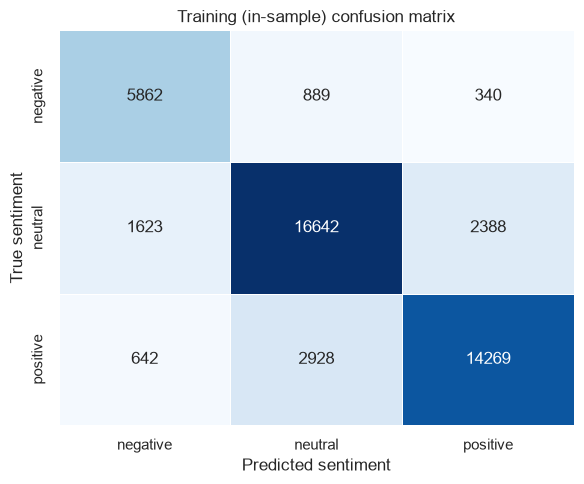

In [22]:
# Show the selected model's training confusion matrix.
from sklearn.metrics import confusion_matrix

training_confusion = confusion_matrix(
    y_train, selected_train_predictions, labels=list(sentiment_labels)
)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    training_confusion, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=label_names, yticklabels=label_names,
    linewidths=0.5, ax=ax,
)
ax.set(
    title="Training (in-sample) confusion matrix",
    xlabel="Predicted sentiment",
    ylabel="True sentiment",
)
fig.tight_layout()
display(fig)
plt.close(fig)


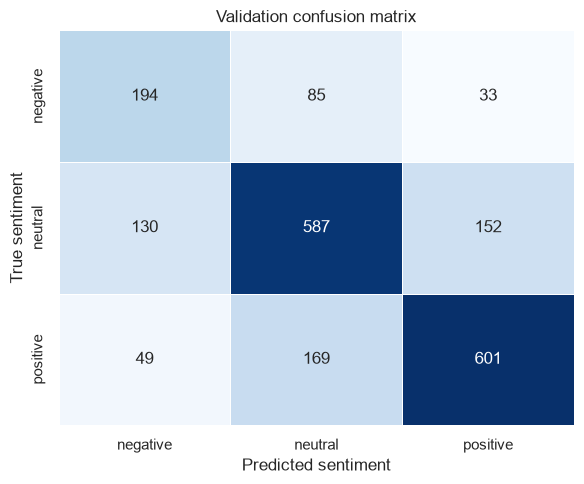

In [23]:
# Show the selected model's validation confusion matrix.
from sklearn.metrics import confusion_matrix

validation_confusion = confusion_matrix(
    y_val, selected_val_predictions, labels=list(sentiment_labels)
)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    validation_confusion, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=label_names, yticklabels=label_names,
    linewidths=0.5, ax=ax,
)
ax.set(
    title="Validation confusion matrix",
    xlabel="Predicted sentiment",
    ylabel="True sentiment",
)
fig.tight_layout()
display(fig)
plt.close(fig)


### Validation model comparison

Macro F1 gives each sentiment equal weight, so it is the main measure used to select the model. The comparison uses validation results only; test results do not affect this ranking. The word-plus-character candidate uses parameters already selected by cross-validation.


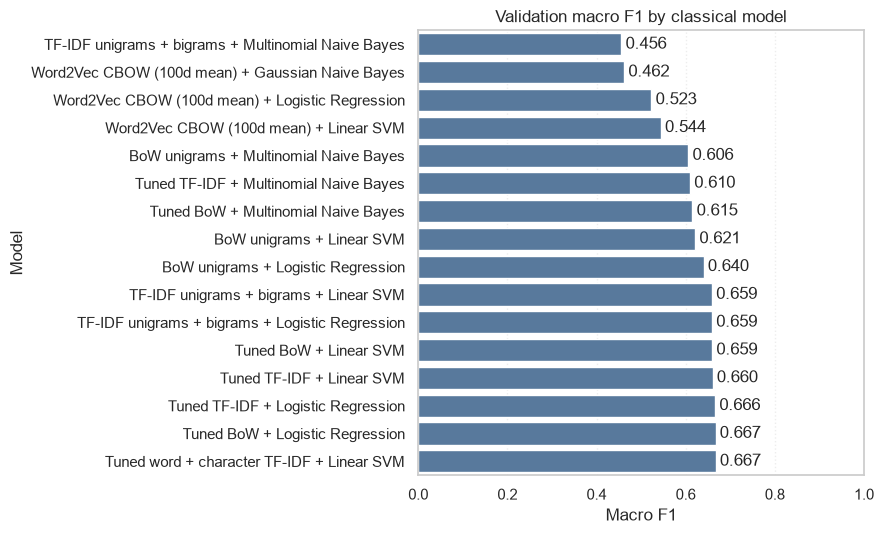

In [24]:
validation_f1 = validation_model_comparison.set_index("Model")[
    "F1-score (macro)"
].sort_values()
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.barplot(
    x=validation_f1.values,
    y=validation_f1.index,
    color="#4C78A8",
    ax=ax,
)
ax.bar_label(ax.containers[0], fmt="%.3f", padding=3)
ax.set(
    title="Validation macro F1 by classical model",
    xlabel="Macro F1",
    ylabel="Model",
    xlim=(0, 1),
)
ax.grid(axis="x", linestyle=":", alpha=0.35)
ax.set_axisbelow(True)
fig.tight_layout()
display(fig)
plt.close(fig)


### 8.4 Refit the selected model

After model selection, refit the winning pipeline on the combined training and validation data. Report training and validation metrics from the model-selection fit, then use the refitted pipeline once for the final test evaluation.

In [25]:
# Refit the validation-selected pipeline on all development data.
import numpy as np
from sklearn.base import clone

final_training_tokens = train_tokens + val_tokens
final_training_labels = np.concatenate([y_train, y_val])
final_pipeline = clone(best_model_info["pipeline"])
final_pipeline.fit(final_training_tokens, final_training_labels)

print("Selected model:", selected_model_name)
print("Development rows used for final fitting:", len(final_training_labels))
print(f"Training accuracy (in-sample): {training_accuracy:.3f}")
print(f"Validation accuracy: {validation_accuracy:.3f}")

Selected model: Tuned word + character TF-IDF + Linear SVM
Development rows used for final fitting: 47583
Training accuracy (in-sample): 0.807
Validation accuracy: 0.691


## 9. Final test evaluation

Refit the validation winner on the combined training and validation splits. Evaluate it once on the official test split; use those results as the final performance estimate.


Test accuracy: 0.635
              precision    recall  f1-score   support

    negative      0.618     0.657     0.637      3972
     neutral      0.673     0.618     0.645      5937
    positive      0.584     0.642     0.612      2375

    accuracy                          0.635     12284
   macro avg      0.625     0.639     0.631     12284
weighted avg      0.638     0.635     0.636     12284



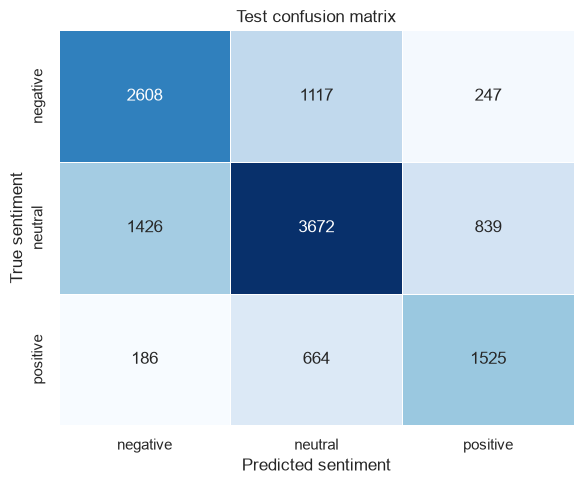

In [26]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

test_tokens = test_df[selected_token_column].tolist()
test_predictions = final_pipeline.predict(test_tokens)
test_accuracy = accuracy_score(y_test, test_predictions)

print(f"Test accuracy: {test_accuracy:.3f}")
print(classification_report(
    y_test, test_predictions, labels=list(sentiment_labels),
    target_names=label_names, digits=3, zero_division=0,
))

confusion_values = confusion_matrix(
    y_test, test_predictions, labels=list(sentiment_labels)
)
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(
    confusion_values, annot=True, fmt="d", cmap="Blues", cbar=False,
    xticklabels=label_names, yticklabels=label_names, linewidths=0.5, ax=ax,
)
ax.set(title="Test confusion matrix", xlabel="Predicted sentiment", ylabel="True sentiment")
fig.tight_layout()
display(fig)
plt.close(fig)

### Misclassified test tweets

Show up test tweets the selected model predicted incorrectly.


In [27]:
error_mask = test_predictions != y_test
error_table = test_df.loc[error_mask, ["text", "sentiment"]].rename(
    columns={"text": "Tweet", "sentiment": "True sentiment"}
).copy()
error_table["Predicted sentiment"] = [
    sentiment_labels[int(label)] for label in test_predictions[error_mask]
]

print(f"Misclassified test tweets: {error_mask.sum()} / {len(test_df)}")
display(error_table.head(20))


Misclassified test tweets: 4479 / 12284


,Tweet,True sentiment,Predicted sentiment
0,@user @user what do these '1/2 naked pics' hav...,neutral,negative
1,OH: “I had a blue penis while I was this” [pla...,neutral,positive
4,"@user Wow,first Hugo Chavez and now Fidel Cast...",negative,neutral
5,Savchenko now Saakashvili took drug test live ...,neutral,negative
10,An interesting security vulnerability - albeit...,neutral,negative
13,"When Ryan privatizes SS, Medicare, Medicaid, &...",negative,neutral
16,OPINION: The Anti-#Trump #Riots Are a #SmokeSc...,neutral,negative
17,ISIS and The CIA What You Need To Know! #ISIS ...,neutral,negative
18,@user alt-right was adopted by Deplorables. Av...,neutral,negative
22,Listen to win passes to see #FantasticBeasts a...,neutral,positive


## 10. Documentation

This notebook uses TweetEval sentiment train, validation, and test splits. It maps label ids to negative, neutral, and positive; inspects class balance and tweet text; reports exact training texts with conflicting labels and removes those ambiguous groups; and removes cross-split text overlap from training and validation while leaving test examples unchanged.

Text preprocessing retains negation, emoji, emoticons, hashtags, and other useful sentiment cues. The notebook compares tokenization options and evaluates BoW, word-level TF-IDF, and mean-pooled Word2Vec baselines. Multinomial Naive Bayes is used with nonnegative BoW and TF-IDF features; Gaussian Naive Bayes is used with continuous Word2Vec vectors. Seven classifier pipelines are tuned with 60 randomized settings each and stratified three-fold cross-validation; the top 20 cross-validation candidates and all baselines are compared on validation macro F1.

The validation winner is refit on the cleaned training and validation data. The held-out test split is evaluated once after model selection. Run the notebook from top to bottom to produce the metrics, classification report, confusion matrices, and examples of misclassified tweets. Scores are estimates on this dataset, and individual predictions can still be wrong.